# 02 小程序 - 模板与配置


本篇是微信小程序基础第 02 天，按原课顺序整理：WXML 模板语法 → WXSS 模板样式 → 全局配置 → 页面配置 → 网络数据请求 → 本地生活首页。

资料依据：[课程网盘](https://pan.baidu.com/s/1crZTQdIZ7OSDkZIpIWkhYw?pwd=1234) 中的 `day02.rar`，包括《00_小程序 - 模板与配置》80 页讲义、目标讲义、`学习目标.txt`、`代码.rar` 中的 `mp_02` 与 `local_life`，以及 `资料.rar` 中的图片。

学完这一篇，应能用 WXML 渲染页面结构、用 WXSS 设置样式、用 `app.json` 配置整个小程序、用页面 JSON 配置单个页面，并通过 `wx.request()` 获取数据。

前五部分在配套项目 `mp_02` 中练习：模板语法主要改 `pages/index/index.*`，网络请求改 `pages/home/home.*`。最后的案例使用独立项目 `local_life`。这些代码写在 Markdown 中供阅读和复制。

> 配套 `mp_02/app.json` 的默认首页是 `pages/home/home`，而 WXML 语法在 `pages/index/index`。练习模板时，在开发者工具的编译模式中指定 `pages/index/index` 为启动页面。源码中的多组 WXML 示例被注释了，练习时按主题逐组启用，避免把所有示例同时放到页面。


## 一、WXML 模板语法

WXML 负责描述页面结构。页面 `.js` 中的 `data` 提供数据，WXML 用数据绑定把内容显示出来；用户点击、输入等操作通过事件交给 JavaScript 处理。

### 1. 数据绑定

数据绑定分两步：先在页面 `data` 中定义数据，再在 WXML 中使用。`{{}}` 叫作 Mustache 语法，里面可以写变量或简单表达式。

下面是 `mp_02/pages/index/index.js` 中与本节相关的数据，放入现有的 `Page({...})` 的 `data` 对象：

```javascript
data: {
  info: 'hello world',
  imgSrc: 'http://www.itheima.com/images/logo.png',
  randomNum1: Math.random() * 10,
  randomNum2: Math.random().toFixed(2)
},
```

在 `pages/index/index.wxml` 中使用：

```xml
<view>{{info}}</view>
<image src="{{imgSrc}}" mode="widthFix"></image>
<view>{{randomNum1 >=5 ? '数字大于或等于5' : '数字小于5'}}</view>
<view>{{randomNum2 * 100}}</view>
```

| 应用场景 | 写法 | 显示含义 |
| --- | --- | --- |
| 绑定内容 | `{{info}}` | 显示 `hello world` |
| 绑定属性 | `src="{{imgSrc}}"` | 图片地址来自 `data` |
| 三元运算 | `{{randomNum1 >= 5 ? ... : ...}}` | 按条件选择要显示的文字 |
| 算术运算 | `{{randomNum2 * 100}}` | 计算后显示结果 |

组件属性仍要用引号包裹；引号内用 `{{}}` 读取变量。`mode="widthFix"` 让图片宽度固定、高度按原图比例调整。

原课图片地址保留如上。若旧地址不能访问，可换成项目中的实际图片路径，数据绑定写法相同。

编译 index 页面，检查文本、图片和两种运算结果。随机数在页面初始化时产生，重新加载页面可能看到不同数值；它不会因为写在 `{{}}` 中就自动持续变化。


### 2. 事件绑定与事件对象

事件是**渲染层到逻辑层的通信方式**：用户在页面上操作，处理函数收到事件对象并执行业务逻辑。

| 事件 | 绑定方式 | 触发行为 |
| --- | --- | --- |
| `tap` | `bindtap` 或 `bind:tap` | 手指触摸后马上离开，类似网页中的点击 |
| `input` | `bindinput` 或 `bind:input` | 文本框输入内容 |
| `change` | `bindchange` 或 `bind:change` | 组件状态改变 |

回调函数通过形参接收事件对象，通常写作 `event` 或 `e`。

| 属性 | 类型 | 含义 |
| --- | --- | --- |
| `type` | String | 事件类型 |
| `timeStamp` | Integer | 页面打开到触发事件经过的毫秒数 |
| `target` | Object | 触发事件的源头组件的属性集合 |
| `currentTarget` | Object | 当前绑定处理函数的组件的属性集合 |
| `detail` | Object | 额外信息，例如输入框的最新值 |
| `touches` | Array | 当前停留在屏幕上的触摸点信息 |
| `changedTouches` | Array | 当前发生变化的触摸点信息 |

#### `target` 与 `currentTarget`

原课示例在外层 `view` 绑定 `tap`，内部放一个按钮：

```xml
<view class="outer-view" bindtap="outerHandler">
  <button type="primary">按钮</button>
</view>
```

点击内层按钮，事件冒泡到外层。在 `outerHandler(e)` 中，`e.target` 是内层按钮，`e.currentTarget` 是绑定处理函数的外层 `view`。

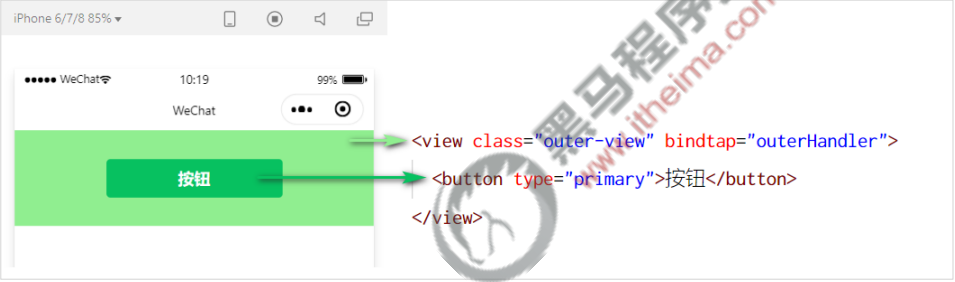

检查时可以在 `outerHandler(e)` 中打印 `e.target` 和 `e.currentTarget`。点击外层空白区域与点击按钮，事件源可能不同；当前绑定处理函数的节点仍是外层 `view`。


### 3. `bindtap`：把按钮与处理函数连接起来

小程序使用 `tap` 响应触摸操作。事件属性只写**函数名**，处理函数定义在当前页面 `Page({...})` 中。

`mp_02/pages/index/index.wxml`：

```xml
<button type="primary" bindtap="btnTapHandler">按钮</button>
```

`pages/index/index.js` 中的对应方法：

```javascript
  btnTapHandler(e) {
    console.log(e)
  },
```

启用这组 WXML 后点击按钮，在控制台查看事件对象，确认 `type` 为 `tap`，并展开节点信息。处理函数的名称必须与 WXML 属性值一致，不能照搬 HTML 的 `onclick` 写法。


### 4. `setData`：修改数据并同步页面

`this.data` 用来读取页面数据，`this.setData({...})` 用来更新数据并同步视图。课程用 `count` 演示按钮加一。

在 index 页的现有 `data` 中加入 `count: 0`。配套 WXML 中的按钮为：

```xml
<button type="primary" bindtap="CountChange">+1</button>
```

配套 `pages/index/index.js` 的方法：

```javascript
  CountChange() {
    this.setData({
      count: this.data.count + 1
    })
  },
```

这里的函数名以大写 `C` 开头，绑定时必须保持相同大小写。读取旧值后加一，再把新值传给 `setData`。

**便于观察的补充**：在按钮旁加一行，把计数直接显示出来：

```xml
<view>当前数量：{{count}}</view>
```

连续点击，页面应从 `0` 逐次增加。只给 `this.data.count` 赋值不能代替 `setData` 的视图同步。


### 5. 事件传参：`data-*` 与 `dataset`

下面是讲义中的错误写法，小程序会把整个 `btnHandler(123)` 当作处理函数名称，而不会执行一次函数调用：

```xml
<!-- 错误写法 -->
<button bindtap="btnHandler(123)">按钮</button>
```

参数要放到组件的 `data-*` 自定义属性中。配套 index 页用 `data-info` 传递数字 `2`：

```xml
<button type="primary" bindtap="btnTap2" data-info="{{2}}">+2</button>
```

处理函数从事件对象的 `dataset` 读取：

```javascript
  btnTap2(e) {
    this.setData({
      count: this.data.count + e.target.dataset.info
    })
  },
```

`data-info` 中的 `info` 是参数名，`{{2}}` 是数值；如果写成 `data-info="2"`，得到的则是字符串。计数从 `0` 开始时点击一次应得到 `2`。

本例按钮本身是事件源，因此源码使用 `e.target.dataset.info`。如果事件绑定在外层节点、点击来源可能是子节点，且参数写在绑定节点上，应从 `e.currentTarget.dataset.info` 读取。两者的选择取决于参数实际在哪个节点。


### 6. `bindinput`：文本框与 `data` 同步

原课步骤是定义数据 → 渲染结构 → 美化样式 → 绑定输入处理函数。最新输入值在 `e.detail.value` 中。

配套 `mp_02/pages/index/index.js` 的 `data` 中定义：

```javascript
msg: '你好，',
```

`pages/index/index.wxml`：

```xml
<input value="{{msg}}" bindinput="inputHandler"></input>
```

`pages/index/index.wxss` 的输入框样式：

```css
input {
  border: 1px solid #eee;
  margin: 5px;
  padding: 5px;
  border-radius: 3px;
}
```

`pages/index/index.js` 的处理函数：

```javascript
  inputHandler(e) {
    // console.log(e.detail.value)
    this.setData({
      msg: e.detail.value
    })
  },
```

`value="{{msg}}"` 把页面数据显示到输入框；`bindinput` 把最新输入交给处理函数，处理函数通过 `setData` 更新 `msg`，完成反向同步。只写 `value` 绑定不会自动把用户输入写回 `data`。

编译后文本框先显示“你好，”。输入新文字，在开发者工具的 AppData 面板检查 `msg`；也可以临时启用源码中的 `console.log(e.detail.value)` 查看最新值。


### 7. 条件渲染：`wx:if`、`block` 与 `hidden`

#### 按条件决定是否渲染

`wx:if="{{condition}}"` 为真时渲染节点。多个互斥分支用 `wx:elif`、`wx:else` 接续。

配套 index 页在 `data` 中定义 `type: 1`，WXML 为：

```xml
<view wx:if="{{type === 1}}">男</view>
<view wx:elif="{{type === 2}}">女</view>
<view wx:else>保密</view>
```

依次将 `type` 改为 `1`、`2`、其他值，重新编译后应分别显示“男”“女”“保密”。

#### 一次控制多个组件

把一组节点包进 `block`，在 `block` 上写条件：

```xml
<block wx:if="{{false}}">
  <view>view1</view>
  <view>view2</view>
</block>
```

`block` 只负责包裹，不是实际渲染组件，不会生成额外可见节点。这里两个 `view` 都不渲染；改成 `true` 后一起出现。

#### 显示与隐藏

`hidden` 为真时隐藏，为假时显示。用配套数据 `flag: true` 比较：

```xml
<view hidden="{{!flag}}">flag 为 true 时显示</view>
<view wx:if="{{flag}}">这是使用 wx:if 控制的元素</view>
```

配套源码第一行的文字写成“条件为 true 的时候隐藏元素，否则显示”，与 `!flag` 的含义容易混淆。这里明确为：`flag=true` → `!flag=false` → 显示；`flag=false` → `!flag=true` → 隐藏。

| 比较项 | `wx:if` | `hidden` |
| --- | --- | --- |
| 运行方式 | 动态创建、移除节点 | 节点保留，通过显示样式切换可见性 |
| 使用建议 | 条件复杂、需要多个分支，或切换不频繁 | 需要频繁显示、隐藏 |

切换同一个 `flag` 时，两段的显示结果相同，但节点的存在方式不同。


### 8. 列表渲染：`wx:for` 与 `wx:key`

`wx:for` 根据数组重复生成组件。默认索引变量为 `index`，当前项变量为 `item`。

`mp_02/pages/index/index.js` 的数组：

```javascript
arr1: ['苹果', '华为', '小米'],
```

WXML：

```xml
<view wx:for="{{arr1}}" wx:key="*this">
  索引是：{{index}}，item 项是：{{item}}
</view>
```

编译后生成三项，索引是 `0`、`1`、`2`。

#### 自定义变量名

`wx:for-index` 设置索引名，`wx:for-item` 设置当前项名：

```xml
<view wx:for="{{arr1}}"
      wx:for-index="idx"
      wx:for-item="itemName"
      wx:key="*this">
  索引是：{{idx}}，item 项是：{{itemName}}
</view>
```

变量名改变，循环内容不变。嵌套循环时可以用不同变量名区分不同层的项目。

#### 给每项稳定、唯一的标识

`wx:key` 帮助框架在数据变化时识别、复用列表项。配套对象数组为：

```javascript
userList: [
  { id: 1, name: '小红' },
  { id: 2, name: '小黄' },
  { id: 3, name: '小白' }
],
```

```xml
<view wx:for="{{userList}}" wx:key="id" class="username">{{item.name}}</view>
```

`wx:key="id"` 取每个数组项的 `id` 属性，不再写 `{{}}`。每项的标识应唯一并保持稳定。

**配套代码修正**：原字符串列表示例写了 `wx:key="index"`、`wx:key="idx"`，这些值会被解释为数组项的属性名，不能直接引用循环索引。本例字符串自身唯一，因此改为 `wx:key="*this"`。若字符串可能重复，应改用带唯一标识的对象数组。


## 二、WXSS 模板样式

WXSS（WeiXin Style Sheets）是美化 WXML 组件的样式语言，具有 CSS 的大部分特性。课程重点讲两个扩展：`rpx` 尺寸单位、`@import` 样式导入，随后区分全局样式与局部样式。

### 1. `rpx` 解决屏幕适配

`rpx` 是 responsive pixel。它把不同设备的屏幕宽度都等分成 **750 份**，所以 `750rpx` 对应当前设备的完整屏幕宽度。

小屏上 `1rpx` 较小，大屏上 `1rpx` 较大。小程序运行时把 `rpx` 换算为实际布局尺寸，从而按屏幕宽度适配。

以原课的 iPhone 6 为例，布局宽度为 `375px`：

```text
750rpx = 375px
1rpx = 0.5px
1px = 2rpx
```

| 原课设备 | `rpx` 换算 `px` | `px` 换算 `rpx` |
| --- | --- | --- |
| iPhone 5 | `1rpx ≈ 0.42px` | `1px ≈ 2.34rpx` |
| iPhone 6 | `1rpx = 0.5px` | `1px = 2rpx` |
| iPhone 6 Plus | `1rpx ≈ 0.552px` | `1px ≈ 1.81rpx` |

换算式为：`px = rpx × 屏幕布局宽度(px) ÷ 750`。

讲义以 iPhone 6 作为视觉稿基准，宽 `100px`、高 `20px` 的盒子换成 `200rpx × 40rpx`。可在当前页面 `.wxss` 中写：

```css
.box {
  width: 200rpx;
  height: 40rpx;
}
```

这是把原课换算结果写成样式的练习示例。给 WXML 节点添加 `class="box"`，切换模拟设备，观察盒子随屏幕宽度变化。

原课还写到 iPhone 6 的 `750` 个物理像素。物理像素与 `px` 的比例取决于设备像素比，不能把“`1rpx = 1` 个物理像素”推广到所有设备。


### 2. 用 `@import` 导入公共样式

`@import` 后写样式表路径，以分号结束。讲义示例把 `common.wxss` 与 `app.wxss` 放在同一目录：

```css
/* common.wxss */
.small-p {
  padding: 5px;
}
```

```css
/* app.wxss */
@import "common.wxss";

.middle-p {
  padding: 15px;
}
```

相对路径从当前 `.wxss` 所在目录计算。配套项目使用另一种目录组织：公共文件在项目根目录的 `common/common.wxss`，内容为：

```css
.username {
  color: red;
}
```

`mp_02/pages/index/index.wxss` 从项目根路径导入：

```css
@import "/common/common.wxss";
```

也可以用与这个目录结构等价的相对路径 `../../common/common.wxss`。列表中 `class="username"` 的用户姓名应显示为红色，说明公共样式已被导入。


### 3. 全局样式与局部样式

| 文件 | 作用范围 |
| --- | --- |
| 项目根目录的 `app.wxss` | 每个页面 |
| 页面自己的 `.wxss` | 当前页面 |

配套 `mp_02/app.wxss` 给所有 `view` 设置间距和浅蓝背景：

```css
view {
  padding: 10rpx;
  margin: 10rpx;
  background-color: lightskyblue;
}

view:nth-child(1) {
  background-color: lightskyblue;
}
```

index 页的局部 `pages/index/index.wxss` 设置浅粉背景：

```css
view {
  background-color: lightpink;
}
```

test 页的 `pages/test/test.wxss` 设置白色文字：

```css
view {
  color: white;
}
```

同等选择器权重下，局部样式覆盖冲突的全局样式；权重更高的全局选择器仍可能胜出。上述 `view:nth-child(1)` 比单独的 `view` 权重高，因此 index 页的第一个 `view` 可能仍保持浅蓝背景。

分别启动 index 与 test 页面，检查背景色、间距和文字颜色。test 页没有局部背景规则时，会继续使用全局背景；局部只改 `color` 不会抹掉其他全局样式。


## 三、全局配置

项目根目录的 `app.json` 配置整个小程序。课程常用字段如下：

| 字段 | 作用 |
| --- | --- |
| `pages` | 注册页面路径，首项是默认启动页面 |
| `window` | 全局设置窗口外观 |
| `tabBar` | 配置多页面切换的页签导航 |
| `style` | 配置新版组件样式，配套项目使用 `"v2"` |

这些节点处在同一层级。JSON 使用双引号，不写注释，最后一项后不要多加逗号。

### 1. 先分清窗口的三个区域

窗口包括导航栏、下拉时露出的背景区域、显示 WXML 的页面主体。

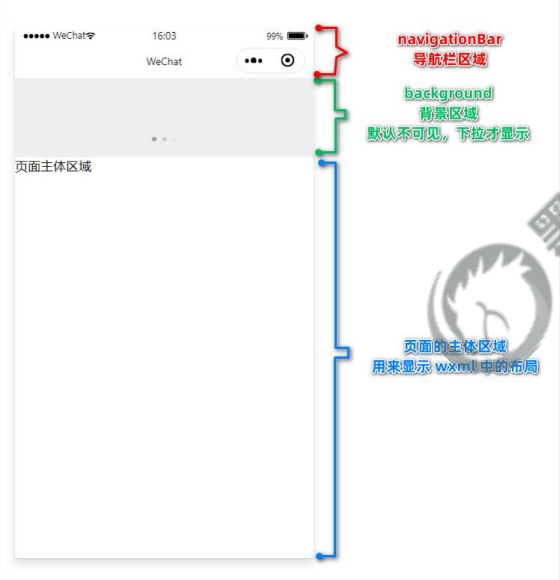

`navigationBar*` 影响顶部导航栏，`backgroundColor` 与 `backgroundTextStyle` 影响下拉背景和 loading；页面组件的背景则通过 WXSS 设置。


### 2. `window` 常用配置

下面默认值来自讲义的配置表。讲义随后截图中的初始外观来自当时项目的已有设置，不能把截图中的白色导航栏当作配置表的默认值。

| 字段 | 类型 | 讲义默认值 | 作用与取值 |
| --- | --- | --- | --- |
| `navigationBarTitleText` | String | 字符串 | 导航栏标题 |
| `navigationBarBackgroundColor` | HexColor | `#000000` | 导航栏背景，使用十六进制颜色 |
| `navigationBarTextStyle` | String | `white` | 标题颜色，仅 `black` 或 `white` |
| `backgroundColor` | HexColor | `#ffffff` | 窗口背景 |
| `backgroundTextStyle` | String | `dark` | 下拉 loading 风格，仅 `dark` 或 `light` |
| `enablePullDownRefresh` | Boolean | `false` | 是否全局开启下拉刷新 |
| `onReachBottomDistance` | Number | `50` | 触底事件距页面底部的距离，单位 `px` |

#### 导航栏：标题、背景、文字颜色

在 `mp_02/app.json` 的现有 `window` 中分别设置：

```json
{
  "navigationBarTitleText": "黑马程序员",
  "navigationBarBackgroundColor": "#2b4b6b",
  "navigationBarTextStyle": "white"
}
```

这个代码块是 `window` 的字段片段。保留原 `window` 中的其他字段，编译后检查标题为“黑马程序员”、背景深蓝、文字白色。`navigationBarTextStyle` 不能填写任意颜色值。

#### 下拉刷新：开关、背景和 loading

下拉刷新指用户向下拉动页面后重新取得页面数据。课程先开启刷新效果，再设置露出的背景和 loading 风格：

```json
{
  "enablePullDownRefresh": true,
  "backgroundColor": "#efefef",
  "backgroundTextStyle": "dark"
}
```

这些字段也合并到 `window` 中。全局开启后，每个页面都具有下拉刷新能力；某个页面可以通过自己的 JSON 覆盖。

编译后下拉页面，检查灰色背景和深色 loading。配置只开启界面能力，实际重新请求数据需要在页面事件中处理，本节未实现刷新业务。

#### 上拉触底：事件距离阈值

`onReachBottomDistance` 指定距离底部多近时触发 `onReachBottom`，默认 `50px`。配套 `mp_02/app.json` 最终设置为 `100`；原课建议没有特殊需求时保留默认值。

```json
{
  "onReachBottomDistance": 100
}
```

这个值不等于自动加载更多数据。需要页面内容能够滚动到相应位置，业务取数写在触底事件中。

配套代码最终的 `window` 保留了灰色背景、深色 loading 和 `100px` 阈值，但没有保留 `enablePullDownRefresh: true`。练习下拉效果时应显式加上刷新开关。


### 3. `tabBar`：页面导航及组成

`tabBar` 用于多页面快速切换，位置可以是底部或顶部。

> `list` 最少 2 项、最多 5 项。顶部 tabBar 只显示文字，不显示图标。

原讲义把未选中、选中状态及其配置关系标在图中：

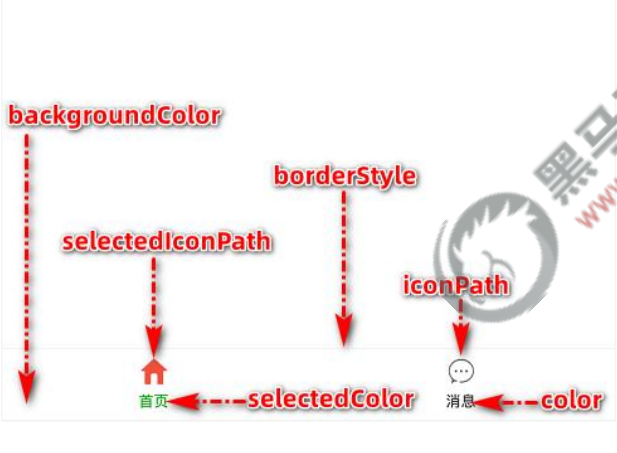

| tabBar 字段 | 类型 | 必填 | 默认值或约束 |
| --- | --- | --- | --- |
| `position` | String | 否 | `bottom`，可选 `bottom` / `top` |
| `borderStyle` | String | 否 | `black`，可选 `black` / `white` |
| `color` | HexColor | 否 | 未选中文字颜色 |
| `selectedColor` | HexColor | 否 | 已选中文字颜色 |
| `backgroundColor` | HexColor | 否 | 导航栏背景颜色 |
| `list` | Array | 是 | 2～5 个页签配置对象 |

每个 `list` 项有以下字段：

| 字段 | 必填 | 含义 |
| --- | --- | --- |
| `pagePath` | 是 | 页面路径，必须已在 `pages` 注册 |
| `text` | 是 | 页签文字 |
| `iconPath` | 否 | 未选中图标的本地路径 |
| `selectedIconPath` | 否 | 已选中图标的本地路径 |

`pagePath` 不带 `.wxml` 等扩展名。图标选中与否由路径对应的图片决定，文字选中颜色由 `selectedColor` 决定。


### 4. 配置“首页、消息、联系我们”三个页签

原课按三个步骤实现：复制图标 → 新建三个页面 → 配置 tabBar。

#### 第一步：复制素材

把课程 `资料/images` 文件夹复制到小程序项目根目录。`images/tabs` 中每组有两张图，带 `-active` 的为选中状态。

| 页签 | 默认图标 | 选中图标 |
| --- | --- | --- |
| 首页 | 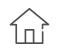 | 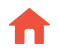 |
| 消息 | 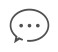 | 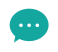 |
| 联系我们 | 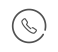 | 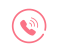 |

#### 第二步：注册页面

在 `app.json.pages` 中添加 `pages/home/home`、`pages/message/message`、`pages/contact/contact`。在微信开发者工具中保存时可以生成对应的四类页面文件；已有的 index、test 等页面路径继续保留。

#### 第三步：设置 tabBar

配套 `mp_02/app.json` 的完整配置如下，包含原有练习页面：

```json
{
  "pages": [
    "pages/home/home",
    "pages/message/message",
    "pages/contact/contact",
    "pages/index/index",
    "pages/test/test",
    "pages/logs/logs"
  ],
  "window": {
    "backgroundTextStyle": "dark",
    "navigationBarBackgroundColor": "#2b4b6b",
    "navigationBarTitleText": "黑马程序员",
    "navigationBarTextStyle": "white",
    "backgroundColor": "#efefef",
    "onReachBottomDistance": 100
  },
  "tabBar": {
    "list": [{
      "pagePath": "pages/home/home",
      "text": "首页",
      "iconPath": "/images/tabs/home.png",
      "selectedIconPath": "/images/tabs/home-active.png"
    },{
      "pagePath": "pages/message/message",
      "text": "消息",
      "iconPath": "/images/tabs/message.png",
      "selectedIconPath": "/images/tabs/message-active.png"
    },{
      "pagePath": "pages/contact/contact",
      "text": "联系我们",
      "iconPath": "/images/tabs/contact.png",
      "selectedIconPath": "/images/tabs/contact-active.png"
    }]
  },
  "style": "v2",
  "sitemapLocation": "sitemap.json"
}
```

`tabBar` 与 `pages`、`window` 平级，`list` 存放三个页签对象。默认打开 home，因此启动时显示 tabBar；打开 index 等非 tab 页面时，不能用是否出现 tabBar 来判断这个配置是否正确。

重新使用默认编译启动 home，依次点击三个页签，检查页面切换、文字及图标状态。图片缺失时先核对 `images/tabs` 中的文件名与配置路径是否一致。


## 四、页面配置

每个页面的 `.json` 用来配置当前页面的窗口外观和效果。`app.json.window` 提供全局设置，页面 JSON 对同名字段进行覆盖；页面没有设置的字段继续采用全局设置。

| 页面字段 | 类型 | 讲义默认值 | 当前页面的作用 |
| --- | --- | --- | --- |
| `navigationBarBackgroundColor` | HexColor | `#000000` | 导航栏背景色 |
| `navigationBarTextStyle` | String | `white` | 导航栏标题色，仅 `black` / `white` |
| `navigationBarTitleText` | String | 字符串 | 标题内容 |
| `backgroundColor` | HexColor | `#ffffff` | 窗口背景色 |
| `backgroundTextStyle` | String | `dark` | 下拉 loading 风格，仅 `dark` / `light` |
| `enablePullDownRefresh` | Boolean | `false` | 是否为当前页面开启下拉刷新 |
| `onReachBottomDistance` | Number | `50` | 触底事件距离，单位 `px` |

**说明用的补充示例**：让消息页使用白色导航栏、黑色标题，并关闭下拉刷新。在 `mp_02/pages/message/message.json` 中写：

```json
{
  "usingComponents": {},
  "navigationBarTitleText": "消息",
  "navigationBarBackgroundColor": "#ffffff",
  "navigationBarTextStyle": "black",
  "enablePullDownRefresh": false
}
```

页面 JSON **直接写配置项，不再包裹 `window`**。这里保留配套文件原有的 `usingComponents`。切到消息页应看到页面自己的标题和颜色，其他页面仍使用全局外观。

配套 day02 的三个页面 JSON 原本仅有 `usingComponents: {}`，上面是为了演示覆盖关系添加的配置，实际复习时可以先比较原文件，再做此练习。


## 五、网络数据请求

### 1. 请求限制与合法域名

课程要求：接口使用 HTTPS，并把接口域名加入小程序的服务器域名信任列表。

以 `https://www.escook.cn` 为例，原课后台路径是：微信小程序管理后台 → 开发 → 开发设置 → 服务器域名 → 修改 request 合法域名。添加的是域名，不是带 `/api/get` 的接口路径。

讲义说明的限制为：支持 HTTPS；不能填写 IP 地址或 `localhost`；需要 ICP 备案；服务器域名每月最多申请 5 次修改。后台菜单与修改次数属于平台规则，实际操作以当前后台提示为准。

本节请求练习在 `mp_02/pages/home/home.js` 与 `.wxml` 中进行，使用 `wx.request()`。


### 2. 发起 GET 请求

`mp_02/pages/home/home.wxml`：

```xml
<button bindtap="getInfo">发起GET请求</button>
```

`pages/home/home.js` 中的配套方法：

```javascript
  getInfo() {
    wx.request({
      url: 'https://www.escook.cn/api/get',
      method: 'GET',
      data: {
        name: 'zs',
        age: 20
      },
      success: (res) => {
        console.log(res.data)
      }
    })
  },
```

| 配置 | 含义 |
| --- | --- |
| `url` | 接口地址 |
| `method: 'GET'` | 请求方式 |
| `data` | 请求参数，本例为 `name` 与 `age` |
| `success` | 收到响应时的回调 |
| `res.data` | 响应正文 |

点击后在控制台查看响应正文，在网络面板核对 `/api/get` 的 GET 请求和参数 `name=zs`、`age=20`。这段代码保留原课地址；接口的实际返回内容以运行时响应为准。


### 3. 发起 POST 请求

`mp_02/pages/home/home.wxml` 的另一个按钮：

```xml
<button bindtap="postInfo">发起POST请求</button>
```

对应 `.js` 的方法：

```javascript
  postInfo() {
    wx.request({
      url: 'https://www.escook.cn/api/post',
      method: "POST",
      data: {
        name: 'ls',
        age: 33
      },
      success: (res) => {
        console.log(res.data)
      }
    })
  },
```

与 GET 示例相比，地址改为 `/api/post`，`method` 改为 `POST`，参数为 `name: 'ls'`、`age: 33`。点击后检查请求方式与数据，再查看 `res.data`。

讲义截图与配套代码中的演示参数不完全相同，本笔记采用配套 `mp_02` 的方法名和参数，保证按钮、代码、说明可以对应。


### 4. 在页面加载时请求初始化数据

页面一打开就需要的数据，在 `onLoad` 中调用获取方法。配套 home 页为：

```javascript
  onLoad: function (options) {
    this.getInfo()
    this.postInfo()
  },
```

保存并重新编译 home，无须点击按钮就应发出两个请求；点击按钮还会再发一次。

两个调用只表示在页面加载时触发，不表示后一个请求等待前一个请求完成。请求回调里使用箭头函数，可沿用页面方法中的 `this`。


### 5. 开发阶段的域名校验选项

讲义介绍：后端暂时只提供 HTTP 接口、尚未准备 HTTPS 时，可以在微信开发者工具中打开“详情 → 本地设置”，勾选“不校验合法域名、TLS 版本以及 HTTPS 证书”，用于临时开发调试。

该选项仅限开发与调试阶段，不能代替正式环境的 HTTPS 和合法域名配置。遇到请求错误时，应先核对接口地址和合法域名，确认是否属于原课讨论的开发环境问题。

### 6. 跨域与 Ajax

原课这里说的跨域问题，指浏览器 Web 开发中的同源限制。小程序的宿主环境是微信客户端，`wx.request` 不受浏览器那套跨域规则约束，但仍受小程序自己的域名规则约束。

Ajax 依赖浏览器的 `XMLHttpRequest`；小程序使用 `wx.request()`，课程称它为“发起网络数据请求”。


## 六、案例：本地生活首页

本节把模板、样式、配置和请求组合起来：顶部导航栏 → 轮播图 → 九宫格分类 → 两张底部图片 → 三个 tab 页签。

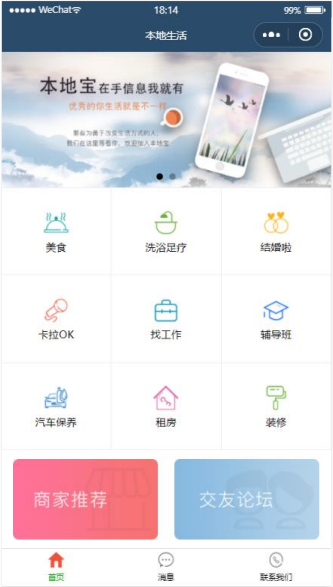

课程步骤为：新建项目并梳理结构、配置导航栏、配置 tabBar、实现轮播图、实现九宫格、实现图片布局。下面使用 `代码.rar` 中的独立 `local_life` 项目，保留这条实现顺序。

### 1. 项目结构与素材

新建小程序项目，注册 home、message、contact 三个页面，保留根目录的应用文件和 sitemap。配套结构为：

```text
local_life/
├─ app.js
├─ app.json
├─ app.wxss
├─ sitemap.json
├─ project.config.json
├─ pages/
│  ├─ home/home.{js,json,wxml,wxss}
│  ├─ message/message.{js,json,wxml,wxss}
│  └─ contact/contact.{js,json,wxml,wxss}
└─ images/
   ├─ tabs/
   │  ├─ home.png、home-active.png
   │  ├─ message.png、message-active.png
   │  └─ contact.png、contact-active.png
   ├─ link-01.png
   └─ link-02.png
```

`{js,json,wxml,wxss}` 是四个同名前缀文件的简写。把课程 `images` 复制到项目根目录，先确认页面和素材实际存在，再写配置。这里的案例只完成首页显示；消息与联系我们页保持配套的占位页面。


### 2. 配置导航栏与 tabBar

编辑 `local_life/app.json`。以下为配套完整配置：

```json
{
  "pages": [
    "pages/home/home",
    "pages/message/message",
    "pages/contact/contact"
  ],
  "window": {
    "backgroundTextStyle": "light",
    "navigationBarBackgroundColor": "#2b4b6b",
    "navigationBarTitleText": "本地生活",
    "navigationBarTextStyle": "white"
  },
  "tabBar": {
    "list": [
      {
        "pagePath": "pages/home/home",
        "text": "首页",
        "iconPath": "/images/tabs/home.png",
        "selectedIconPath": "/images/tabs/home-active.png"
      },
      {
        "pagePath": "pages/message/message",
        "text": "消息",
        "iconPath": "/images/tabs/message.png",
        "selectedIconPath": "/images/tabs/message-active.png"
      },
      {
        "pagePath": "pages/contact/contact",
        "text": "联系我们",
        "iconPath": "/images/tabs/contact.png",
        "selectedIconPath": "/images/tabs/contact-active.png"
      }
    ]
  },
  "style": "v2",
  "sitemapLocation": "sitemap.json"
}
```

`pages` 注册三个页面，home 为默认首页。`window` 设置标题“本地生活”、深蓝背景、白色标题；`tabBar.list` 将页面与图标连接起来。

先编译检查导航栏，再依次切换三个页签，确认页面路径和图标正常。配套项目没有在这里实现下拉刷新，也不要把 `mp_02` 的练习样式全部复制进案例。


### 3. 实现轮播图：先取数据，再渲染，再设置尺寸

原课接口为：`GET https://www.escook.cn/slides`。响应数组的项目在页面结构中使用 `id`、`image`。

编辑 `local_life/pages/home/home.js`：在现有 `data` 中准备空数组，在 `Page({...})` 中加入获取方法。下面组合成便于阅读的页面片段：

```javascript
Page({
  data: {
    // 存放轮播图数据的列表
    swiperList: []
  },

  getSwiperList() {
    wx.request({
      url: 'https://www.escook.cn/slides',
      method: 'GET',
      success: (res) => {
        this.setData({
          swiperList: res.data
        })
      }
    })
  }
})
```

此处为轮播阶段的片段，后面继续向同一个 `Page` 的 `data` 和方法区域加入九宫格，不要创建第二个 `Page`。

在现有 `onLoad` 中调用 `this.getSwiperList()`。请求成功后通过 `setData` 把 `res.data` 写入数组，WXML 才有数据可遍历。

`pages/home/home.wxml` 的轮播区域：

```xml
<swiper indicator-dots circular>
  <swiper-item wx:for="{{swiperList}}" wx:key="id">
    <image src="{{item.image}}"></image>
  </swiper-item>
</swiper>
```

`indicator-dots` 显示指示点，`circular` 允许循环衔接；原课没有设置自动播放。`wx:key="id"` 用项目的 id 标识轮播项。

`pages/home/home.wxss`：

```css
swiper {
  height: 350rpx;
}

swiper image {
  width: 100%;
  height: 100%;
}
```

先在网络面板确认取到数组，再检查页面图片、指示点和手动滑动。数据为空时轮播区域可能没有图片，不能只凭空白区域判断是 WXSS 问题。


### 4. 实现九宫格：数据列表与三列布局

原课接口为：`GET https://www.escook.cn/categories`。每项在 WXML 中使用 `id`、`icon`、`name`。

在同一 `pages/home/home.js` 的 `data` 中增加 `gridList: []`，加入配套方法：

```javascript
  getGridList() {
    wx.request({
      url: 'https://www.escook.cn/categories',
      method: 'GET',
      success: (res) => {
        this.setData({
          gridList: res.data
        })
      }
    })
  },
```

在现有 `onLoad` 中再调用 `this.getGridList()`。

`pages/home/home.wxml` 的九宫格区域：

```xml
<view class="grid-list">
  <view class="grid-item" wx:for="{{gridList}}" wx:key="id">
    <image src="{{item.icon}}"></image>
    <text>{{item.name}}</text>
  </view>
</view>
```

`pages/home/home.wxss`：

```css
.grid-list {
  display: flex;
  flex-wrap: wrap;
  border-left: 1rpx solid #efefef;
  border-top: 1rpx solid #efefef;
}

.grid-item {
  width: 33.33%;
  height: 200rpx;
  display: flex;
  flex-direction: column;
  align-items: center;
  justify-content: center;
  border-right: 1rpx solid #efefef;
  border-bottom: 1rpx solid #efefef;
  box-sizing: border-box;
}

.grid-item image {
  width: 60rpx;
  height: 60rpx;
}

.grid-item text {
  font-size: 24rpx;
  margin-top: 10rpx;
}
```

父容器使用 Flex 换行，每项宽 `33.33%`，因此每行三列。每项内部纵向居中排列图标和文字。

父容器负责上、左边框，子项负责右、下边框，构成网格。`box-sizing: border-box` 把边框计入每项宽度，避免三列加上边框后超宽。

编译后检查分类图标和名称是否来自响应；九项数据应形成三行三列。这里完成分类展示，尚未添加点击分类后的页面跳转。


### 5. 实现底部两张图片的布局

配套原图分别用于“商家推荐”和“交友论坛”：

| 商家推荐 | 交友论坛 |
| --- | --- |
| 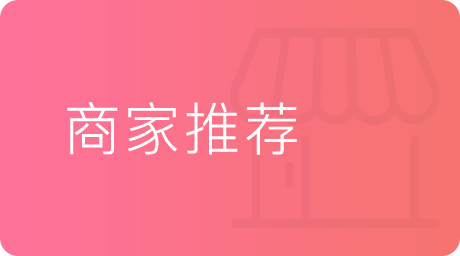 | 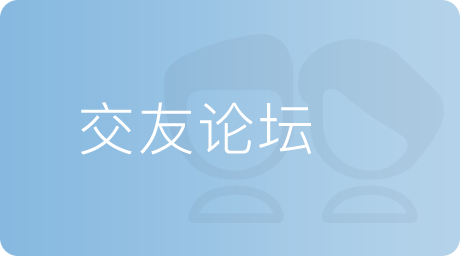 |

在 `local_life/pages/home/home.wxml` 的九宫格后加入：

```xml
<view class="img-box">
  <image src="/images/link-01.png" mode="widthFix"></image>
  <image src="/images/link-02.png" mode="widthFix"></image>
</view>
```

`pages/home/home.wxss`：

```css
.img-box {
  display: flex;
  padding: 20rpx 10rpx;
  justify-content: space-around;
}

.img-box image {
  width: 45%;
}
```

两张图片各占容器宽度的 `45%`，`space-around` 留出横向间隔，`widthFix` 根据宽度自动计算高度，保持原图比例。

图片路径以项目根目录为起点。编译后应看到两张本地图并排显示；如果显示空白，先确认 `images/link-01.png`、`images/link-02.png` 已复制且名称正确。


### 6. 首页最终的数据逻辑

轮播与九宫格写在同一个页面。下面按配套源码保留最终有效逻辑，省略自动生成、尚未使用的空生命周期方法：

```javascript
Page({
  data: {
    // 存放轮播图数据的列表
    swiperList: [],
    // 存放九宫格数据的列表
    gridList: []
  },

  onLoad: function (options) {
    this.getSwiperList()
    this.getGridList()
  },

  getSwiperList() {
    wx.request({
      url: 'https://www.escook.cn/slides',
      method: 'GET',
      success: (res) => {
        this.setData({
          swiperList: res.data
        })
      }
    })
  },

  getGridList() {
    wx.request({
      url: 'https://www.escook.cn/categories',
      method: 'GET',
      success: (res) => {
        this.setData({
          gridList: res.data
        })
      }
    })
  }
})
```

WXML 按前面三个区域顺序组合，WXSS 合并对应的轮播、九宫格和图片样式。

本代码沿用课程的 `res.data` 直接为数组的响应约定。运行时先查看响应结构，再确认轮播项的 `id/image` 与分类项的 `id/icon/name`；旧接口地址或图片失效时应对照课程更新资料，不能把不同结构的响应直接塞进列表。


### 7. 按实现顺序验证首页

1. **文件与配置**：三个页面都存在，`pages` 与 `tabBar.list` 的路径一致，home 是默认启动页。
2. **导航和页签**：显示“本地生活”及深蓝导航栏，三个页签可切换，选中与默认图标对应。
3. **轮播请求**：首页加载时发出 `/slides` 请求，返回数组后显示轮播图和指示点，可手动切换。
4. **分类请求**：发出 `/categories` 请求，分类按三列布局，每项显示图标和名称。
5. **底部图片**：两张本地图片并排、保持比例，路径与素材一致。
6. **适配效果**：切换模拟设备，检查 `350rpx` 轮播高度、九宫格宽度与图片间距。

以上是运行案例时的检查步骤。本笔记已核对讲义和源码，未把微信开发者工具中尚未执行的请求或页面效果写成运行结果。

原课总结对应五项能力：WXML 的绑定与渲染、WXSS 的适配与样式组织、`app.json` 的全局配置、页面 JSON 的覆盖关系、`wx.request()` 与 `onLoad()` 的初始化取数。
